# EDA

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df=pd.read_csv(r'D:\3. Machine Learning\Day 2\Tugas\titanic.csv')

In [4]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
df.tail()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [7]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [8]:
df.describe(include='object')

,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Braund, Mr. Owen Harris",male,347082,B96 B98,S
freq,1,577,7,4,644


In [9]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

ada 891 penumpang dan 12 kolom. nilai kosong ada di age 177, cabin 687 dan embarked 2

In [10]:
df.Pclass.value_counts()

3    491
1    216
2    184
Name: Pclass, dtype: int64

In [11]:
df.groupby('Pclass').Survived.value_counts()

Pclass  Survived
1       1           136
        0            80
2       0            97
        1            87
3       0           372
        1           119
Name: Survived, dtype: int64

In [12]:
df[['Pclass','Survived']].groupby('Pclass',as_index=False).mean()

,Pclass,Survived
0,1,0.629630
1,2,0.472826
2,3,0.242363


<AxesSubplot:xlabel='Pclass', ylabel='Survived'>

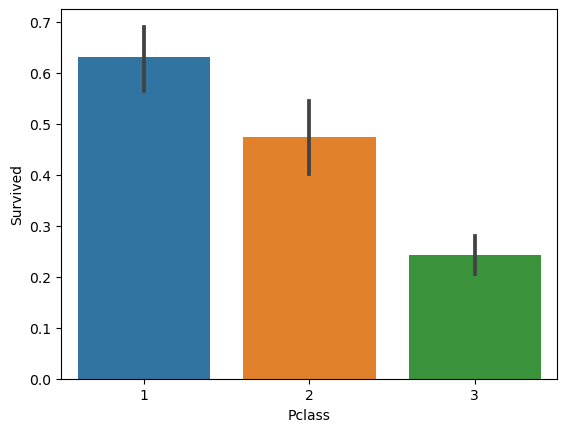

In [13]:
sns.barplot(x='Pclass',y='Survived',data=df)

kelas 3 memiliki penumpang terbanyak. proporsi selamat kelas 1 2 dan 3 adalah 62,96%, 47,28% dan 24,24%

In [14]:
df['Sex'].value_counts()

male      577
female    314
Name: Sex, dtype: int64

In [15]:
df.groupby('Sex').Survived.value_counts()

Sex     Survived
female  1           233
        0            81
male    0           468
        1           109
Name: Survived, dtype: int64

In [16]:
df[['Sex','Survived']].groupby('Sex',as_index=False).mean()

,Sex,Survived
0,female,0.742038
1,male,0.188908


<AxesSubplot:xlabel='Sex', ylabel='Survived'>

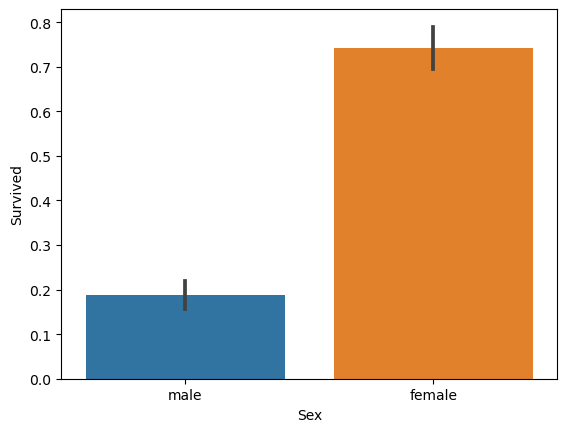

In [17]:
sns.barplot(x='Sex',y='Survived',data=df)

proporsi selamat perempuan 74,20% sedangkan laki-laki 18,89%

In [18]:
df[['Pclass','Sex','Survived']].groupby(['Pclass','Sex'],as_index=False).mean()

,Pclass,Sex,Survived
0,1,female,0.968085
1,1,male,0.368852
2,2,female,0.921053
3,2,male,0.157407
4,3,female,0.500000
5,3,male,0.135447


<AxesSubplot:xlabel='Pclass', ylabel='Survived'>

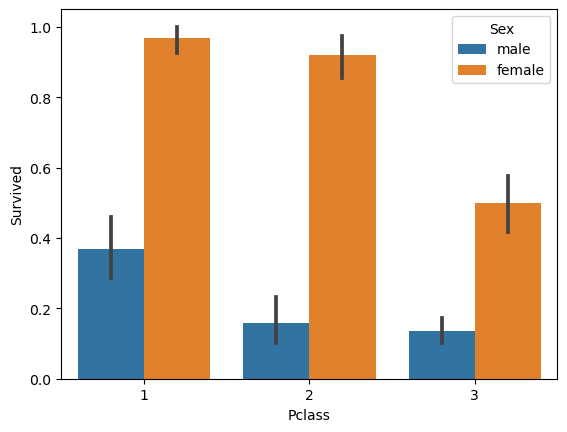

In [19]:
sns.barplot(x='Pclass',y='Survived',hue='Sex',data=df)

perempuan memiliki proporsi selamat lebih tinggi pada setiap kelas tiket

In [20]:
df['Age'].describe()

count    714.000000
mean      29.699118
std       14.526497
min        0.420000
25%       20.125000
50%       28.000000
75%       38.000000
max       80.000000
Name: Age, dtype: float64

In [21]:
df[['Survived','Age']].groupby('Survived',as_index=False).mean()

,Survived,Age
0,0,30.626179
1,1,28.343690


<AxesSubplot:xlabel='Age', ylabel='Count'>

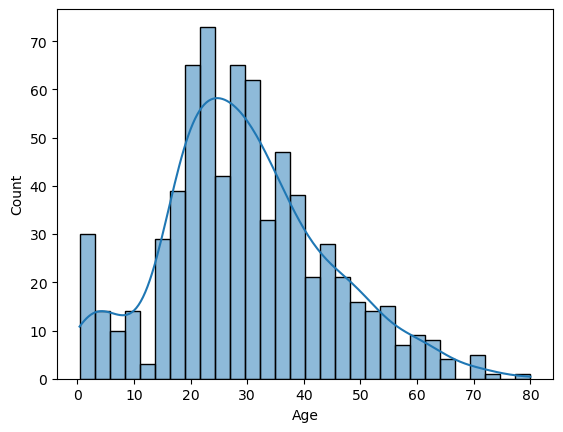

In [22]:
sns.histplot(x='Age',data=df,kde=True,bins=30)

<AxesSubplot:xlabel='Survived', ylabel='Age'>

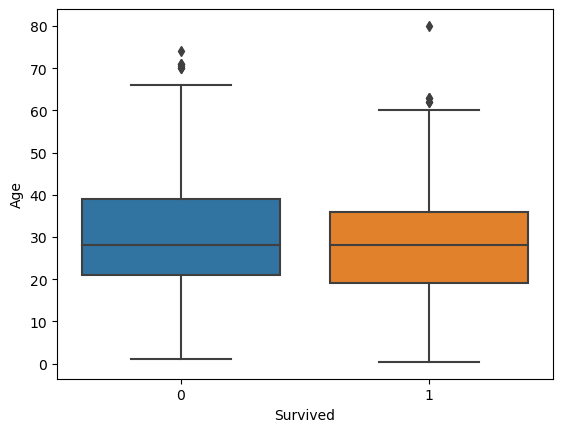

In [23]:
sns.boxplot(x='Survived',y='Age',data=df)

umur banyak berada di sekitar 20-40 tahun, dengan rata-rata 29,70 tahun. umur kedua kelompok banyak bertumpang tindih. nilai umur yang kosong tidak ikut dihitung

In [24]:
df[['Survived','Fare']].groupby('Survived',as_index=False).mean()

,Survived,Fare
0,0,22.117887
1,1,48.395408


<AxesSubplot:xlabel='Survived', ylabel='Fare'>

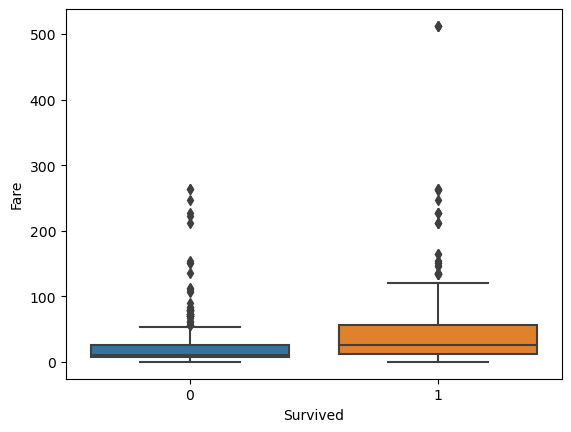

In [25]:
sns.boxplot(x='Survived',y='Fare',data=df)

tarif miring ke kanan: rata-rata 32,20 dan median 14,45. rata-rata tarif kelompok selamat 48,40, sedangkan yang tidak selamat 22,12. tarif tinggi belum tentu salah, jadi tetap dipakai

<AxesSubplot:xlabel='Age', ylabel='Fare'>

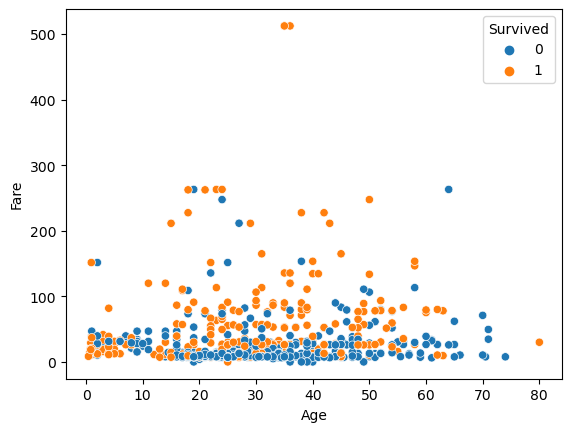

In [26]:
sns.scatterplot(x='Age',y='Fare',hue='Survived',data=df)

titik kedua kelompok banyak bertumpuk. umur dan tarif perlu dilihat bersama fitur lain

In [27]:
df[['Embarked','Survived']].groupby('Embarked',as_index=False).mean()

,Embarked,Survived
0,C,0.553571
1,Q,0.389610
2,S,0.336957


<AxesSubplot:xlabel='Embarked', ylabel='Survived'>

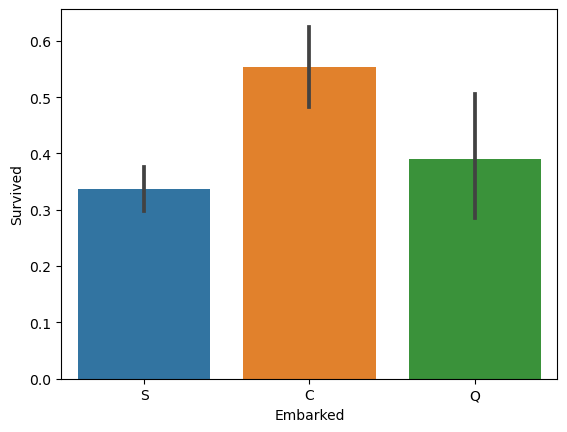

In [28]:
sns.barplot(x='Embarked',y='Survived',data=df)

proporsi selamat dari pelabuhan c, q, dan s adalah 55,36%, 38,96%, dan 33,70%

<AxesSubplot:>

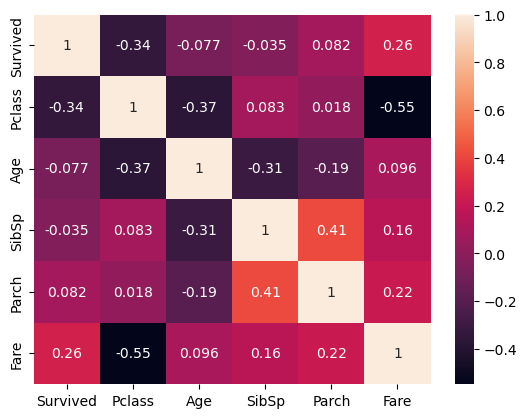

In [29]:
sns.heatmap(df[['Survived','Pclass','Age','SibSp','Parch','Fare']].corr(),annot=True)

korelasi dengan keselamatan adalah -0,34 untuk pclass, 0,26 untuk fare, dan -0,08 untuk age. angka kelas yang lebih besar berarti kelas tiket lebih rendah

# Data Preprocessing

In [30]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [31]:
df_clean=df.copy()

age diisi median karena tidak terlalu dipengaruhi nilai ekstrem. embarked diisi modus karena berupa kategori.
cabin dihapus karena 77,10% kosong. passengerid hanya pengenal. name dan ticket berupa teks dengan banyak nilai unik

In [32]:
df_clean['Age']=df_clean['Age'].fillna(df_clean['Age'].median())
df_clean['Embarked']=df_clean['Embarked'].fillna(df_clean['Embarked'].mode()[0])
df_clean=df_clean.drop(columns=['Cabin','Name','Ticket','PassengerId'])
df_clean.isnull().sum()

Survived    0
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64

sex diubah menjadi 0 untuk laki-laki dan 1 untuk perempuan. embarked memakai one-hot encoding karena tidak memiliki urutan. pclass tetap 1, 2, 3 karena kelas tiket berurutan

In [33]:
df_clean['Sex']=df_clean['Sex'].map({'male':0,'female':1})
df_clean=pd.get_dummies(df_clean,columns=['Embarked'],dtype=int)
df_clean.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S
0,0,3,0,22.0,1,0,7.2500,0,0,1
1,1,1,1,38.0,1,0,71.2833,1,0,0
2,1,3,1,26.0,0,0,7.9250,0,0,1
3,1,1,1,35.0,1,0,53.1000,0,0,1
4,0,3,0,35.0,0,0,8.0500,0,0,1


age dan fare memakai standardscaler karena satuan dan rentangnya berbeda. rata-ratanya menjadi sekitar 0 dan standar deviasinya 1. kolom lainnya tidak diskalakan

In [34]:
from sklearn.preprocessing import StandardScaler

scaler=StandardScaler()
df_clean[['Age','Fare']]=scaler.fit_transform(df_clean[['Age','Fare']])
df_clean.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S
0,0,3,0,-0.565736,1,0,-0.502445,0,0,1
1,1,1,1,0.663861,1,0,0.786845,1,0,0
2,1,3,1,-0.258337,0,0,-0.488854,0,0,1
3,1,1,1,0.433312,1,0,0.420730,0,0,1
4,0,3,0,0.433312,0,0,-0.486337,0,0,1


In [35]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Survived    891 non-null    int64  
 1   Pclass      891 non-null    int64  
 2   Sex         891 non-null    int64  
 3   Age         891 non-null    float64
 4   SibSp       891 non-null    int64  
 5   Parch       891 non-null    int64  
 6   Fare        891 non-null    float64
 7   Embarked_C  891 non-null    int32  
 8   Embarked_Q  891 non-null    int32  
 9   Embarked_S  891 non-null    int32  
dtypes: float64(2), int32(3), int64(5)
memory usage: 59.3 KB


# Logistic Regression

In [36]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

In [37]:
X=df_clean.drop(columns=['Survived']).copy()
y=df_clean['Survived'].copy()

In [38]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=42)

In [39]:
model=LogisticRegression()
model.fit(X_train,y_train)

LogisticRegression()

In [40]:
y_pred=model.predict(X_test)
y_pred

array([0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0,
       1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0,
       1, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1,
       0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 0, 0, 0, 1, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0,
       1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0,
       0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 1,
       0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0,
       0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 0,
       1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0,
       0, 1, 0, 0, 0, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1,
       0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0,
       0, 0, 0, 0], dtype=int64)

In [41]:
from sklearn.metrics import classification_report

print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.82      0.87      0.84       157
           1       0.79      0.73      0.76       111

    accuracy                           0.81       268
   macro avg       0.81      0.80      0.80       268
weighted avg       0.81      0.81      0.81       268



In [42]:
from sklearn.metrics import confusion_matrix

cm=confusion_matrix(y_test,y_pred,labels=[0,1])
cm

array([[136,  21],
       [ 30,  81]], dtype=int64)

Text(0.5, 1.0, 'Confusion Matrix')

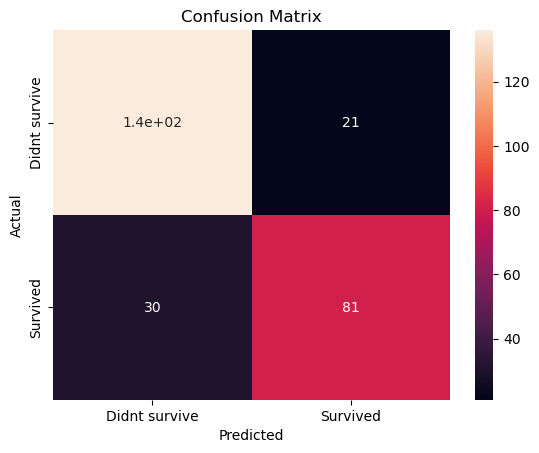

In [43]:
sns.heatmap(cm,annot=True,xticklabels=['Didnt survive','Survived'],yticklabels=['Didnt survive','Survived'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')

In [44]:
from sklearn.metrics import accuracy_score,f1_score,precision_score,recall_score,roc_auc_score

accuracy_score(y_test,y_pred)

0.8097014925373134

In [45]:
f1_score(y_test,y_pred,zero_division=0)

0.7605633802816901

In [46]:
precision_score(y_test,y_pred,zero_division=0)

0.7941176470588235

In [47]:
recall_score(y_test,y_pred,zero_division=0)

0.7297297297297297

In [48]:
y_proba=model.predict_proba(X_test)[:,1]
roc_auc=roc_auc_score(y_test,y_proba)
roc_auc

0.8805302117404028

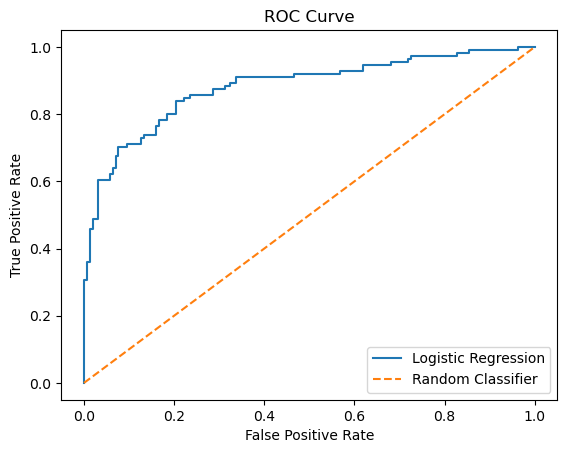

In [49]:
from sklearn.metrics import roc_curve

fpr,tpr,thresholds=roc_curve(y_test,y_proba)
plt.plot(fpr,tpr,label=f'Logistic Regression')
plt.plot([0,1],[0,1],'--',label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()

In [50]:
tn,fp,fn,tp=cm.ravel()
print('TN:',tn)
print('FP:',fp)
print('FN:',fn)
print('TP:',tp)
print('False +rate:',fp/(tn+fp))
print('False -rate:',fn/(tp+fn))

TN: 136
FP: 21
FN: 30
TP: 81
False +rate: 0.1337579617834395
False -rate: 0.2702702702702703


- TN = 136: tidak selamat dan diprediksi tidak selamat
- FP = 21: tidak selamat tetapi diprediksi selamat
- FN = 30: selamat tetapi diprediksi tidak selamat
- TP = 81: selamat dan diprediksi selamat

model benar pada 217 dari 268 penumpang, sehingga akurasinya 80,97%. dari 102 prediksi selamat, 81 benar-benar selamat; precision 79,41%. dari 111 penyintas, 81 dikenali; recall 72,97%.

30 penyintas terlewat, yaitu 27,03% dari seluruh penyintas pada testing. 21 penumpang yang tidak selamat keliru diprediksi selamat, yaitu 13,38% dari kelompok tidak selamat. model mengenali 86,62% penumpang yang tidak selamat